# Figure 5d
The unbiased fitness $r^*$ against the population size $N$. The unbiased fitness is the mutant fitness with $p_1=1/2$, found by linear interpolation between the two values of $r$ around the first crossing of $1/2$ on the curves of panel b.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt

from fixloc import style as S

d = json.load(open('data.json'))
rs = np.array(d['r'])

In [2]:
Ns = list(range(10, 31, 2))
rstar = []
for N in Ns:
  y = np.array(d['p1'][str(N)]) - 0.5
  k = int(np.flatnonzero(np.diff(np.sign(y)) != 0)[0])
  rstar.append(rs[k] - y[k] * (rs[k + 1] - rs[k]) / (y[k + 1] - y[k]))

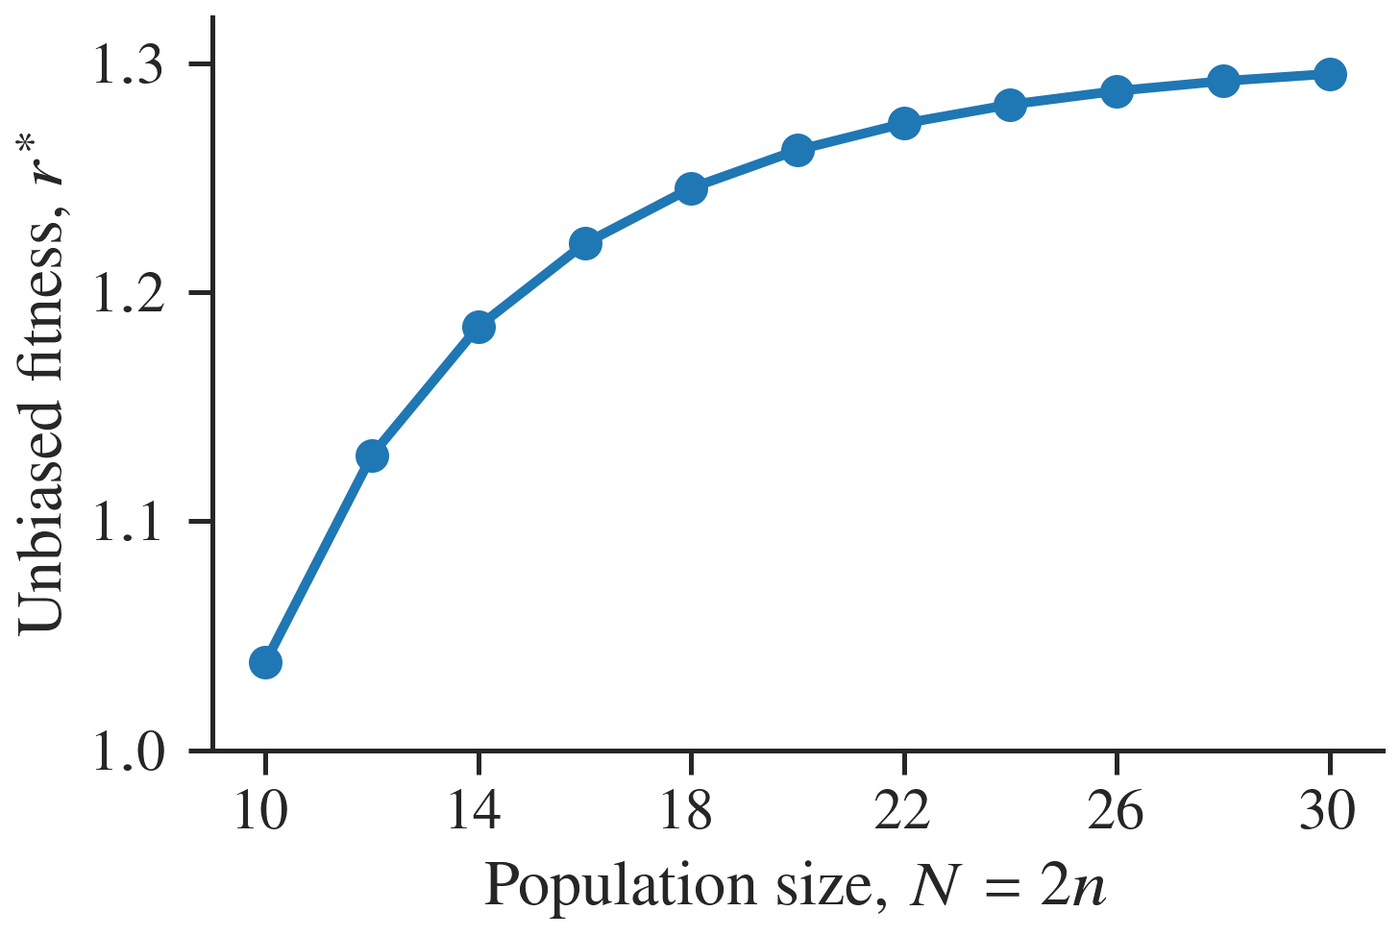

In [3]:
fig = plt.figure(figsize=(7.0, 6.2))
ax = fig.add_axes([0.6, 0.385, 0.29, 0.205])
ax.plot(Ns, rstar, color=S.BLUE, lw=1.2, marker='o', ms=3.2)
ax.set_xticks(Ns[::2])
ax.set_xlim(9, 31)
ax.set_ylim(1.0, 1.32)
ax.set_yticks([1.0, 1.1, 1.2, 1.3])
ax.set_xlabel(r'Population size, $N=2n$')
ax.set_ylabel(r'Unbiased fitness, $r^*$')
S.save_panel(fig, 'd')